In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
# from sentence_transformers import SentenceTransformer
import pandas as pd
import numpy as np
import scipy as sp
from math import ceil
import matplotlib.pyplot as plt
import torch
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from hdbscan import HDBSCAN as ALThdb
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import RidgeCV
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import f1_score, make_scorer, accuracy_score
from xgboost import XGBClassifier
import umap
import os
import time
from lightgbm.sklearn import LGBMClassifier, LGBMRegressor
import seaborn as sns
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
import pingouin as pg
from statsmodels.stats.multitest import multipletests
import statsmodels.stats.proportion as prop
from pprint import pprint
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split

from sklearn.base import BaseEstimator, TransformerMixin

import os

Mach Regression

In [2]:
data = pd.read_csv('data_processed.csv')

In [3]:
X = data.drop(['major', 'country', 'MachScr', 'KindScr', *[f"Q{i}E" for i in range(1,21)], *[f"Q{i}I" for i in range(1,21)], *[f'Q{i}A' for i in range(1, 21)]], axis=1).set_index('Unnamed: 0')
y = data['MachScr']

In [4]:
X.head()

,introelapse,testelapse,surveyelapse,TIPI1,TIPI2,TIPI3,TIPI4,TIPI5,TIPI6,TIPI7,...,hand,religion,orientation,race,voted,married,familysize,cluster,LiarSum,IsLiar
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
0,49.0,328.0,426,6,5,6,1,7,3,7,...,1,7,1,30,1,2,2,78,1,1
1,38.0,143.0,150,2,5,6,2,4,6,5,...,1,1,1,60,2,1,2,53,0,0
2,4.0,143.0,157,1,7,6,7,5,7,1,...,1,2,2,10,2,1,2,19,3,1
3,60.0,191.0,269,6,5,5,7,7,2,6,...,1,6,1,60,1,3,2,8,1,1
4,37.0,302.0,334,2,5,5,6,7,6,5,...,1,4,3,60,1,1,2,78,0,0


In [5]:
class AddPCA(BaseEstimator, TransformerMixin):
    def __init__(self, n_components=0.95):
        self.n_components = n_components
        self.pca = PCA(n_components=self.n_components)
        self.feature_names_ = None

    def fit(self, X, y=None):
        self.pca.fit(X)
        self.feature_names_ = [f'pca_{i}' for i in range(self.pca.n_components_)]
        return self

    def transform(self, X, y=None):
        pca_features = self.pca.transform(X)
        
        pca_df = pd.DataFrame(
            pca_features,
            index=X.index,
            columns=self.feature_names_
        )
        
        return pd.concat([X, pca_df], axis=1)

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return self.feature_names_
        return list(input_features) + self.feature_names_

In [6]:
X

,introelapse,testelapse,surveyelapse,TIPI1,TIPI2,TIPI3,TIPI4,TIPI5,TIPI6,TIPI7,...,hand,religion,orientation,race,voted,married,familysize,cluster,LiarSum,IsLiar
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
0,49.0,328.0,426,6,5,6,1,7,3,7,...,1,7,1,30,1,2,2,78,1,1
1,38.0,143.0,150,2,5,6,2,4,6,5,...,1,1,1,60,2,1,2,53,0,0
2,4.0,143.0,157,1,7,6,7,5,7,1,...,1,2,2,10,2,1,2,19,3,1
3,60.0,191.0,269,6,5,5,7,7,2,6,...,1,6,1,60,1,3,2,8,1,1
4,37.0,302.0,334,2,5,5,6,7,6,5,...,1,4,3,60,1,1,2,78,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146974,6.0,494.0,340,6,4,5,2,6,6,6,...,1,12,1,10,2,2,1,78,0,0
146975,6.0,295.0,140,5,7,5,5,5,6,3,...,1,2,3,60,2,1,2,80,0,0
146976,11.0,111.0,122,1,6,1,5,5,6,3,...,1,1,1,60,2,1,3,26,0,0


In [7]:
class AddTIPISums(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        # Метод fit всегда должен возвращать self
        return self

    def transform(self, X, y=None):
        # Делаем явную копию, чтобы не изменять оригинальный DataFrame (SettingWithCopyWarning)
        X_copy = X.copy()
        
        # Списки колонок (проверьте, нужны ли здесь TIPI6, 9, 10)
        neg_TIPI = [f'TIPI{e}' for e in (2, 4, 8, 10)]
        pos_TIPI = [f'TIPI{e}' for e in (1, 3, 5, 7, 9)]

        # Прямо создаем новые колонки в скопированном датафрейме
        X_copy['neg_TIPI_sum'] = X_copy[neg_TIPI].sum(axis=1)
        X_copy['pos_TIPI_sum'] = X_copy[pos_TIPI].sum(axis=1)
        
        return X_copy


In [8]:
class AddMultiplicationFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        # Метод fit всегда должен возвращать self
        return self

    def transform(self, X, y=None):
        # Делаем явную копию, чтобы не изменять оригинальный DataFrame (SettingWithCopyWarning)
        X_copy = X.copy()

        # Прямо создаем новые колонки в скопированном датафрейме
        X_copy['multi_gend_edu'] = X_copy['gender'] * X_copy['education']
        X_copy['multi_tipi7_age'] = X_copy['TIPI7'] * X_copy['age']
        
        return X_copy


In [9]:
class AddFamilyFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        # Метод fit всегда должен возвращать self
        return self

    def transform(self, X, y=None):
        # Делаем явную копию, чтобы не изменять оригинальный DataFrame (SettingWithCopyWarning)
        X_copy = X.copy()

        # Прямо создаем новые колонки в скопированном датафрейме
        X['alone'] = 1 if (X['married'] == 0 and X['familysize'] == 0) else 0
        
        return X_copy


In [10]:
# 1. Настройка предобработки колонок
# Применяем OneHotEncoder к категориальным признакам, остальные оставляем как есть
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), [ 'cluster', 'religion', 'race']),
    ],
    remainder='passthrough'
)

preprocessor.set_output(transform="pandas")
model = Pipeline(steps=[
    ('tipi_sums', AddTIPISums()),
    ('multi_feat', AddMultiplicationFeatures()),
    ('preprocessor', preprocessor),
    # ('pca', AddPCA(n_components=0.95)),
    ('model', XGBRegressor(
        n_estimators=400,
        learning_rate=0.1,
        max_depth=7,
        random_state=42,
        objective='reg:absoluteerror')
        ),
    ],
)

In [13]:
data['education'].value_counts()

education
2    54174
3    49550
4    25512
1    15946
0     1760
Name: count, dtype: int64

In [11]:
-cross_val_score(model, X, y, scoring='neg_mean_absolute_error', cv=5)

KeyboardInterrupt: 

In [ ]:
imp = pd.DataFrame(model[-1].feature_importances_, index=model[-1].feature_names_in_)

<Axes: xlabel='0', ylabel='None'>

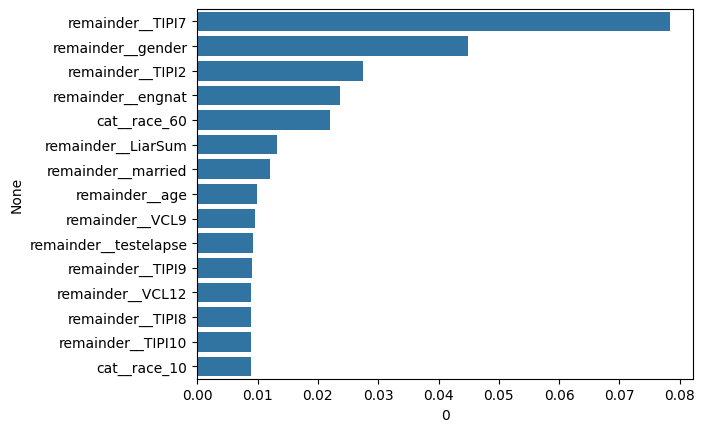

In [ ]:
sns.barplot(y=imp.sort_values(by=0, ascending=False)[:15].index, x=imp.sort_values(by=0, ascending=False)[0][:15], )

In [ ]:
data['education']

array([5.0225279 , 5.01389399, 4.97448486])
baseline

array([5.08286936, 5.09031664, 5.0800881 , 5.09064516, 5.11910244])
PCA only

array([5.01093575, 4.96755785, 4.93765414])
TIPI_SUM 
neg_TIPI = [f'TIPI{e}' for e in (2, 4, 8)]
pos_TIPI = [f'TIPI{e}' for e in (1, 3, 5, 7)]

array([5.05041485, 4.97348408, 4.98351416])
TIPI_SUM
neg_TIPI = [f'TIPI{e}' for e in (2, 4, 8, 9)]
pos_TIPI = [f'TIPI{e}' for e in (1, 3, 5, 7, 6)] smth like that


logarithmised target
nono

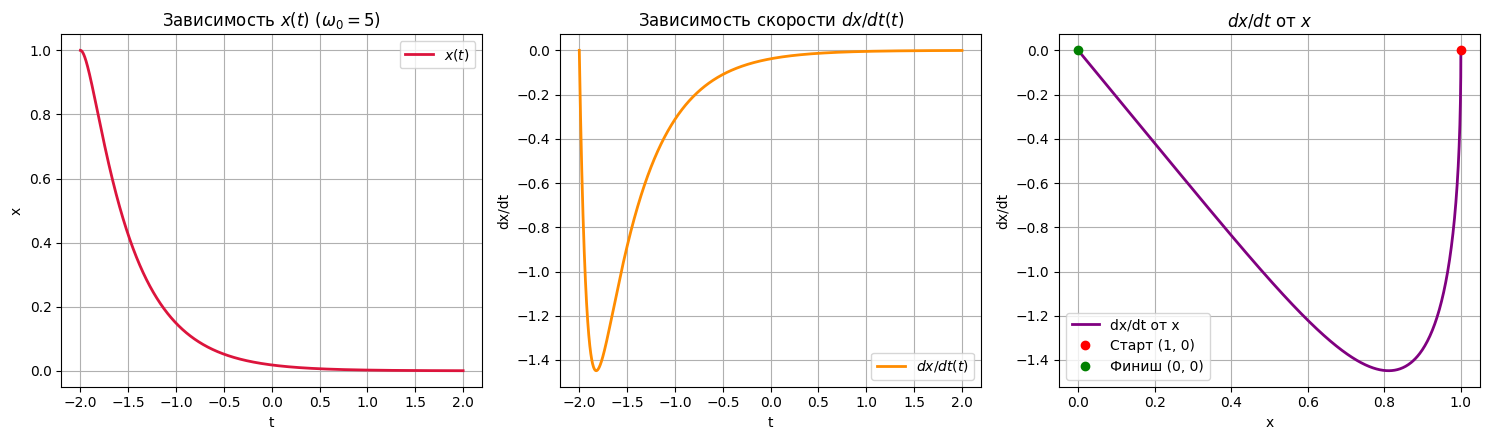

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

gamma = 7
w0 = 5.0

# Система дифференциальных уравнений:
# dx/dt = v
# dv/dt = -2*gamma*v - w0^2*x
def system(y, t):
    x, v = y
    return [v, -2 * gamma * v - (w0**2) * x]

t = np.linspace(-2, 2, 4000)
y0 = [1.0, 0.0]  # x(0) = 1, v(0) = 0

sol = odeint(system, y0, t)
x = sol[:, 0]
v = sol[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Смещение x(t)
axes[0].plot(t, x, color='crimson', lw=2, label=r'$x(t)$')
axes[0].set_title(r'Зависимость $x(t)$ ($\omega_0 = 5$)')
axes[0].set_xlabel('t')
axes[0].set_ylabel('x')
axes[0].grid(True)
axes[0].legend()

# 2. Скорость dx/dt от t
axes[1].plot(t, v, color='darkorange', lw=2, label=r'$dx/dt(t)$')
axes[1].set_title(r'Зависимость скорости $dx/dt(t)$')
axes[1].set_xlabel('t')
axes[1].set_ylabel('dx/dt')
axes[1].grid(True)
axes[1].legend()

# 3. dx/dt от x
axes[2].plot(x, v, color='purple', lw=2, label='dx/dt от x')
axes[2].plot(1, 0, 'ro', label='Старт (1, 0)')
axes[2].plot(0, 0, 'go', label='Финиш (0, 0)')
axes[2].set_title(r'$dx/dt$ от $x$')
axes[2].set_xlabel('x')
axes[2].set_ylabel('dx/dt')
axes[2].grid(True)
axes[2].legend()

plt.tight_layout()
plt.show()